**Proyecto Sombreros de Levine**
Facundo Solari y Pascal Soto

In [1]:
import itertools, time, math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
DEV = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| dispositivo:", DEV)

torch 2.11.0 | dispositivo: cpu


In [2]:

def contenidos_np(t):
    """Los n = 2^t - 2 contenidos no monocromáticos de un bloque, como matriz 0/1 (n x t), orden lexicográfico."""
    return np.array(list(itertools.product([0, 1], repeat=t)), dtype=np.int8)[1:-1]
def q_mono(t): return Fraction(2, 2 ** t)
def r_critico(t):
    q = q_mono(t); return (7 - 3 * q) / (20 * (1 - q))
def valor_infinito(r, t):
    q = q_mono(t); return ((1 - q) * r + q / 2) / (1 + q)
def valor_h(r, t, d):
    q = q_mono(t); P = (1 - q) * (1 - q ** (2 * d)) / (1 + q); return P * r + (1 - P) / 4
def umbral(h): return (7 * 4 ** h) // 20               # victorias que hay que SUPERAR en h sombreros para refutar 7/20
def formato_paper(k, t): return ["-"] + [int(v) + 1 for v in k] + ["-"]

In [3]:
# Acá empieza el contenido en el que se usó asistencia de IA, se mencionará especificamente
def pilas_aleatorias(B, h):
    """B pilas uniformes de h sombreros (0/1). Nunca se enumeran las 2^h pilas."""
    return (torch.rand(B, h, device=DEV) < 0.5).float()

def gumbel_like(z): return -torch.log(-torch.log(torch.rand_like(z) + 1e-20) + 1e-20) #Esto lo sugirió la IA, metodo softmax/gumbel

def E_pares(P, X): # Estimador de la esperanza de productos punto  E[(p(x)·y)(p(y)·x)] 
    A = P @ X.T                                   # A[a,b] = p_a · x_b
    B = A.shape[0]; dg = A.diagonal()
    return ((A * A.T).sum() - (dg ** 2).sum()) / (B * (B - 1))

@torch.no_grad()  #implementación de IA, para evaluar la estrategia encontrada frente al caso óptimo para h dado
def evaluar_mc(pol, h, M=200_000, trozo=20_000, seed=123):
    """Prob. de ganar de la estrategia DURA (argmax) con pilas frescas: M partidas independientes (x, y), sirve para h grande.
    Devuelve (p, error estándar)."""
    torch.manual_seed(seed); gana = 0; tot = 0
    for _ in range(max(1, M // trozo)):
        x = pilas_aleatorias(trozo, h); y = pilas_aleatorias(trozo, h)
        lx, ly = pol.nivel(x), pol.nivel(y); idx = torch.arange(trozo, device=DEV)
        gana += (y[idx, lx] * x[idx, ly]).sum().item(); tot += trozo       # quien ve x nombra un nivel de y, y viceversa
    p = gana / tot; return p, math.sqrt(p * (1 - p) / tot)

@torch.no_grad()
def evaluar_exacto(pol, h, h_max=12):
    """Victorias EXACTAS sobre las 4^h configuraciones (solo evaluación; viable hasta h = 12; con h = 13 la matriz 2^h x 2^h ya pesa cientos de MB)."""
    assert h <= h_max, f"h={h} es demasiado grande para enumerar; usa evaluar_mc o la fórmula exacta de bloques"
    N = 1 << h
    X = ((torch.arange(N, device=DEV).unsqueeze(1) >> torch.arange(h - 1, -1, -1, device=DEV)) & 1).float()   # todas las pilas
    lv = torch.cat([pol.nivel(X[i:i + 65536]) for i in range(0, N, 65536)])
    A = X[:, lv].T.to(torch.int8)                 # A[x,y] = y[lv[x]]
    return int((A * A.T).sum(dtype=torch.int64).item())          # entero exacto (sin errores de redondeo float32)

def umbral_h(h): return umbral(h)

In [4]:
# El desarrollo de estos códigos (más no la idea) se genera con IA. Se construye la red sin información previa en PoliticaMLP 
# Y se construye la red inspirandose en la estrategia de saltar bloques monocromáticos
class PoliticaMLP(nn.Module):
    """Sin estructura previa: una red que mira la pila COMPLETA (h bits) y devuelve h logits (qué nivel nombrar).
    Es la forma más general de estrategia simétrica, pero con h grande no puede enumerarse ni evaluarse exacta."""
    def __init__(self, h, ancho=256, capas=3):
        super().__init__(); L = []; d = h
        for _ in range(capas): L += [nn.Linear(d, ancho), nn.GELU()]; d = ancho
        L.append(nn.Linear(d, h)); self.net = nn.Sequential(*L); self.h = h
    def logits(self, X): return self.net(2 * X - 1)
    def probs(self, X, tau, ruido):
        l = self.logits(X); return torch.softmax((l + ruido * gumbel_like(l)) / tau, dim=1)
    @torch.no_grad()
    def nivel(self, X): return self.logits(X).argmax(1)

class PoliticaBloques(nn.Module):
    """
    Estrategia por bloques con tabla APRENDIDA: se leen los bloques de t sombreros de la pila que se ve, se saltan los
    monocromáticos y en el primer bloque no monocromático de contenido c se nombra el nivel  t*b + k_theta(c)  de la pila propia.
    Lo aprendido es k_theta (t bits -> t logits): una tabla libre ('tabla', 2^t x t parámetros) o una red pequeña ('mlp').
    Lo que NO se aprende es la regla de 'saltar monocromáticos'; funciona para cualquier h >= t (el costo crece solo con h).
    La política es diferenciable: p = sum_b [parar en b] * (one-hot del bloque b  ⊗  softmax(k_theta(c_b)/tau)); si todos los
    bloques son monocromáticos se nombra el nivel 0.
    """
    def __init__(self, h, t, param="mlp", ancho=128):
        super().__init__(); assert h >= t; self.h, self.t, self.d, self.param = h, t, h // t, param
        if param == "tabla": self.tab = nn.Parameter(0.5 * torch.randn(2 ** t, t))
        else: self.net = nn.Sequential(nn.Linear(t, ancho), nn.GELU(), nn.Linear(ancho, ancho), nn.GELU(), nn.Linear(ancho, t))
        self.register_buffer("pot", 2 ** torch.arange(t - 1, -1, -1))
    def _logits_bloques(self, V):                                    # V: (..., t) bits -> (..., t) logits
        if self.param == "tabla": return self.tab[(V * self.pot).sum(-1).long()]
        return self.net(2 * V - 1)
    def _parar(self, X):
        B = X.shape[0]; V = X[:, :self.d * self.t].reshape(B, self.d, self.t); s = V.sum(2)
        nomono = ((s > 0) & (s < self.t)).float()                    # (B, d)
        prev = torch.cat([torch.ones(B, 1, device=X.device), torch.cumprod(1 - nomono, dim=1)[:, :-1]], dim=1)
        return V, prev * nomono                                      # one-hot del primer bloque no monocromático (o todo ceros)
    def probs(self, X, tau, ruido):
        B = X.shape[0]; V, parar = self._parar(X); l = self._logits_bloques(V)         # (B, d, t)
        pk = torch.softmax((l + ruido * gumbel_like(l)) / tau, dim=2)
        P = (parar.unsqueeze(2) * pk).reshape(B, self.d * self.t)
        P = F.pad(P, (0, self.h - self.d * self.t))
        e0 = torch.zeros(self.h, device=X.device); e0[0] = 1.0
        return P + (1 - parar.sum(1, keepdim=True)) * e0             # todos monocromáticos -> nivel 0
    @torch.no_grad()
    def nivel(self, X):
        B = X.shape[0]; V, parar = self._parar(X); hay = parar.sum(1) > 0; j = parar.argmax(1)
        k = self._logits_bloques(V)[torch.arange(B, device=X.device), j].argmax(1)
        return torch.where(hay, self.t * j + k, torch.zeros_like(j))
    @torch.no_grad()
    def tabla_dura(self):
        """La tabla aprendida, endurecida: nivel elegido (0..t-1) para cada contenido no monocromático (orden lexicográfico)."""
        C = torch.tensor(contenidos_np(self.t), dtype=torch.float32, device=DEV)
        return self._logits_bloques(C).argmax(1).cpu().numpy()

@torch.no_grad()
def W_exacto_tabla(k, t, trozo=2048):
    """W' exacto de la tabla k sobre los n contenidos no monocromáticos: sum_{a,b} Xn[b,k[a]] Xn[a,k[b]], por trozos (sin matriz n x n)."""
    Xn = torch.tensor(contenidos_np(t), dtype=torch.int8, device=DEV); k = torch.as_tensor(k, device=DEV).long(); W = 0
    Xk = Xn[:, k]                                                  # Xk[b,a] = Xn[b,k[a]]
    for i in range(0, len(k), trozo):
        W += int((Xk[:, i:i + trozo].T * Xn[i:i + trozo][:, k]).sum(dtype=torch.int64).item())   # [a,b]: Xn[b,k[a]] * Xn[a,k[b]]
    return W

def valor_exacto_bloques(pol, h=None):
    """Valor EXACTO (racional) de la estrategia de bloques endurecida, para cualquier h, sin enumerar: r desde W' y la fórmula."""
    t = pol.t; n = 2 ** t - 2; k = pol.tabla_dura(); W = W_exacto_tabla(k, t); r = Fraction(W, n * n)
    d = pol.d if h is None else h // t
    return dict(W=W, n=n, r=r, r_crit=r_critico(t), W_crit=r_critico(t) * n * n, V_inf=valor_infinito(r, t), V_h=valor_h(r, t, d), k=k)

In [5]:
# El entrenamiento, los gráficos y las tablas fueron programados con IA en su totalidad (nuevamente, no la idea, si no que
# se genera en base a lo pedido)
def _E_dura(pol, h, eval_B=4096):
    """Probabilidad de ganar de la estrategia endurecida (argmax), para la curva de entrenamiento.
    Bloques: exacta (por la fórmula, vía W' de la tabla). MLP con h <= 12: exacta por enumeración. Si no: estimada con un lote."""
    with torch.no_grad():
        if isinstance(pol, PoliticaBloques) and pol.t <= 12:
            t = pol.t; n = 2 ** t - 2; r = Fraction(W_exacto_tabla(pol.tabla_dura(), t), n * n); return float(valor_h(r, t, pol.d))
        if h <= 12: return evaluar_exacto(pol, h) / 4 ** h
        X = pilas_aleatorias(eval_B, h); Ph = F.one_hot(pol.nivel(X), h).float(); return E_pares(Ph, X).item()

def entrenar(pol, h, steps=6000, lote=2048, lr=None, tau0=1.0, tau1=0.05, ruido0=3.0, ent_w=0.05, every=100, seed=0, log=1000):
    """
    Maximiza  E[(p(x)·y)(p(y)·x)]  (estimada con `lote` pilas aleatorias frescas por paso, E_pares) con Adam y cosine decay:
      * p = softmax((logits + ruido*Gumbel)/tau): tau baja de tau0 a tau1 (geométrico) y el ruido baja linealmente a 0;
      * penalización de entropía que sube linealmente (empuja a estrategias deterministas).
    La estrategia es simétrica por construcción (los dos jugadores usan la misma política).  No hay búsqueda local ni enumeración.
    Devuelve hist: paso, tau, E_suave (lote), E_dura (estrategia endurecida), entropia, seg (segundos de ENTRENAMIENTO acumulados en cada registro,
    sin contar la evaluación de E_dura) y tiempo (total).
    """
    torch.manual_seed(seed); pol.to(DEV)
    lr = lr if lr is not None else (0.05 if getattr(pol, "param", None) == "tabla" else 3e-3)
    opt = torch.optim.Adam(pol.parameters(), lr=lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    hist = {k_: [] for k_ in ("paso", "tau", "E_suave", "E_dura", "entropia", "seg")}; t0 = time.time(); t_eval = 0.0
    for it in range(steps):
        frac = it / steps; tau = tau0 * (tau1 / tau0) ** frac
        X = pilas_aleatorias(lote, h); P = pol.probs(X, tau, ruido0 * (1 - frac))
        E = E_pares(P, X); ent = -(P * torch.log(P + 1e-12)).sum(1).mean()
        loss = -E + ent_w * frac * ent
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if it % every == 0 or it == steps - 1:
            te = time.time(); ed = _E_dura(pol, h); t_eval += time.time() - te      # la evaluación periódica no cuenta como tiempo de entrenamiento
            for k_, v_ in (("paso", it), ("tau", tau), ("E_suave", E.item()), ("E_dura", ed), ("entropia", ent.item()), ("seg", time.time() - t0 - t_eval)): hist[k_].append(v_)
            if log and (it % log == 0 or it == steps - 1):
                print(f"  paso {it:5d}  tau={tau:.3f}  E_suave={E.item():.4f}  E_dura={ed:.5f}  entropía={ent.item():.3f}  {time.time()-t0:.0f}s", flush=True)
    hist["tiempo"] = time.time() - t0
    return hist

def informe_bloques(pol, h, hist=None, M=200_000):
    """Resultado exacto (fórmula) y Monte Carlo de una política de bloques entrenada, para su h (puede ser enorme)."""
    v = valor_exacto_bloques(pol, h); t = pol.t; d = h // t; W_h = v["V_h"] * 4 ** h
    p, se = evaluar_mc(pol, h, M=M); u = umbral(h)
    print(f"t={t}, h={h} ({d} bloques): W'={v['W']} de n²={v['n']**2}  (W*={float(v['W_crit']):.2f}, margen {v['W']-float(v['W_crit']):+.2f})")
    print(f"  r={float(v['r']):.5f} (r*={float(v['r_crit']):.5f})   V_inf={float(v['V_inf']):.6f}   V_h exacto={float(v['V_h']):.6f}")
    print(f"  victorias exactas en h={h}: " + (f"{int(W_h)} frente a umbral {u}  ->  " + ("SUPERA" if W_h > u else "no supera") if W_h.denominator == 1 and h <= 30 else "(número enorme; ver V_h)"))
    print(f"  Monte Carlo ({M} partidas): {p:.5f} ± {se:.5f}   (z = {(p-float(v['V_h']))/max(se,1e-12):+.2f} frente a la fórmula)")
    return v, p, se

def informe_mlp(pol, h, M=200_000):
    """Resultado de una política MLP (sin estructura): exacta por enumeración si h <= 12; si no, Monte Carlo."""
    if h <= 12:
        W = evaluar_exacto(pol, h); u = umbral(h)
        print(f"h={h}: victorias exactas {W} de {4**h}  (p={W/4**h:.5f})  umbral {u}  déficit {W-u:+d}  ({100*W/u:.2f} % del umbral)"); return W / 4 ** h, 0.0
    p, se = evaluar_mc(pol, h, M=M); print(f"h={h}: Monte Carlo {p:.5f} ± {se:.5f}  (7/20 = 0.35000)"); return p, se

In [6]:
def graficar_entrenamiento(hist, pol, h, titulo=""):
    """Izq.: E_suave (lote, con ruido y temperatura) y E_dura (estrategia endurecida) frente a 7/20 y al umbral de ese h.
    Centro: temperatura y entropía. Der.: qué niveles nombra la estrategia endurecida (en piezas de 4096 pilas frescas)."""
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2)); p = hist["paso"]
    ax[0].plot(p, hist["E_suave"], alpha=.6, label="E_suave (lote, con ruido y τ)"); ax[0].plot(p, hist["E_dura"], lw=2, label="E_dura: la misma función en la estrategia determinista (argmax)")
    ax[0].axhline(0.35, color="k", ls=":", label="7/20")
    if h <= 40: ax[0].axhline(umbral(h) / 4 ** h, color="tab:red", ls="--", lw=1, label=f"umbral h={h}")
    ax[0].axhline(0.25, color="gray", ls=":", lw=1); ax[0].set_xlabel("paso"); ax[0].set_ylabel("prob. de ganar"); ax[0].set_title("Entrenamiento: " + titulo); ax[0].legend(fontsize=7)
    ax[1].plot(p, hist["tau"], color="tab:orange"); ax[1].set_yscale("log"); ax[1].set_xlabel("paso"); ax[1].set_ylabel("τ", color="tab:orange")
    a2 = ax[1].twinx(); a2.plot(p, hist["entropia"], color="tab:green"); a2.set_ylabel("entropía de la política", color="tab:green"); ax[1].set_title("Estabilización: τ↓ y entropía↓")
    with torch.no_grad(): lv = pol.nivel(pilas_aleatorias(4096, h)).cpu().numpy()
    ax[2].hist(lv, bins=np.arange(h + 1) - 0.5, color="tab:purple"); ax[2].set_xlabel("nivel nombrado (0 = más bajo)"); ax[2].set_ylabel("frecuencia (4096 pilas)")
    ax[2].set_title("Niveles que usa la estrategia dura")
    for a in (ax[0], ax[1]): a.grid(alpha=.3)
    fig.tight_layout(); plt.show()

In [7]:
# ---------- Entrenar varios métodos y compararlos: tiempo hasta estabilizar, costo y exactitud ----------
EPS_ESTAB = 1e-3      # "estabilizó" = E_dura queda a menos de EPS_ESTAB de su valor final desde ahí hasta el final

def paso_estab(hist, eps=EPS_ESTAB):
    """Primer registro desde el cual |E_dura - E_dura_final| <= eps en ese y en TODOS los siguientes. Devuelve (paso, segundos de entrenamiento)."""
    e = np.asarray(hist["E_dura"]); mal = np.where(np.abs(e - e[-1]) > eps)[0]; j = 0 if len(mal) == 0 else mal[-1] + 1
    return hist["paso"][j], hist["seg"][j]

def correr(metodo, fabrica, h, lote, steps, seed, every=50):
    """Entrena UNA política (simétrica) con un método y devuelve: curva, tiempos y su valor EXACTO: victorias W, margen W - umbral(h) y,
    en bloques, W' y el margen W' - W* (el criterio para h infinito: W' > W* refutaría 7/20)."""
    pol = fabrica(h).to(DEV); hist = entrenar(pol, h, steps=steps, lote=lote, seed=seed, every=every, log=0); Wp = Wc = k = None
    if isinstance(pol, PoliticaBloques):
        v = valor_exacto_bloques(pol, h); W = v["V_h"] * 4 ** h; Wp, Wc, k = v["W"], v["W_crit"], v["k"]       # fórmula exacta, vale para cualquier h
    else: W = Fraction(evaluar_exacto(pol, h))                                                                # enumeración (h <= 12)
    u = umbral(h); p_est, s_est = paso_estab(hist)
    return dict(metodo=metodo, h=h, pol=pol, hist=hist, W=W, umbral=u, frac=float(W / u), deficit=float(W - u), seg_total=hist["seg"][-1],
                paso_estab=p_est, seg_estab=s_est, steps=steps, lote=lote, seed=seed, Wp=Wp, Wcrit=Wc, k=k,
                margen_W=(None if Wp is None else float(Wp - Wc)))

def experimento(res, nombre, fabrica, hs, semillas=(0, 1), lote=512, steps=2500, every=50):
    """Entrena `nombre` para cada h de `hs` y cada semilla, y guarda las corridas en res[(nombre, h)] (res es un dict compartido por los métodos).
    Mismo lote y mismos pasos para todos los métodos: así los tiempos son comparables."""
    T0 = time.time()
    for h in hs:
        res[(nombre, h)] = []
        for s in semillas:
            r = correr(nombre, fabrica, h, lote, steps, s, every); res[(nombre, h)].append(r)
            print(f"  {nombre:<20} h={h:<4} semilla {s}: {100*r['frac']:7.3f} % del umbral (déficit {r['deficit']:+.3g} victorias) | "
                  f"estabiliza en el paso {r['paso_estab']:>5} ({r['seg_estab']:5.1f} s de {r['seg_total']:5.1f} s)   [{time.time()-T0:.0f} s]", flush=True)
    return res

def _m(res, clave, metodo, h):
    v = np.array([r[clave] for r in res[(metodo, h)]], dtype=float); return v.mean(), v.std()

def graficar_tiempo_vs_h(res):
    """Fig. 2 (por método): tiempo hasta estabilizar frente a h, SUPERPUESTO sobre el tiempo total de entrenamiento (izq.); iteraciones hasta
    estabilizar (centro); exactitud final = % del umbral (der.). Barras = media de semillas, líneas = desviación estándar."""
    metodos = sorted({m for m, _ in res}); fig, ax = plt.subplots(1, 3, figsize=(16, 4.2)); col = plt.cm.tab10(np.arange(len(metodos)))
    todas_h = sorted({h for _, h in res}); ancho = 0.8 / len(metodos)
    for i, m in enumerate(metodos):
        hs = sorted(h for mm, h in res if mm == m); x = np.array([todas_h.index(h) for h in hs]) - 0.4 + ancho * (i + .5)
        tot = [_m(res, "seg_total", m, h) for h in hs]; est = [_m(res, "seg_estab", m, h) for h in hs]
        ax[0].bar(x, [a for a, _ in tot], ancho, color=col[i], alpha=.35, label=f"{m}: total")
        ax[0].bar(x, [a for a, _ in est], ancho * .55, yerr=[b for _, b in est], color=col[i], capsize=2, label=f"{m}: hasta estabilizar")
        it = [_m(res, "paso_estab", m, h) for h in hs]; ax[1].bar(x, [a for a, _ in it], ancho, yerr=[b for _, b in it], color=col[i], capsize=2, label=m)
        fr = [_m(res, "frac", m, h) for h in hs]; ax[2].bar(x, [100 * a for a, _ in fr], ancho, yerr=[100 * b for _, b in fr], color=col[i], capsize=2, label=m)
    ax[2].axhline(100, color="k", ls="--", lw=1, label="umbral (100 %)"); ax[2].set_ylim(max(0, min(100 * r["frac"] for R in res.values() for r in R) - 3), 100.6)
    for a, t_, yl in zip(ax, ("Tiempo: hasta estabilizar (oscuro) sobre total (claro)", "Iteraciones hasta estabilizar", "Exactitud final"),
                         ("segundos de entrenamiento", "paso", "% del umbral ⌊7·4^h/20⌋")):
        a.set_xticks(range(len(todas_h))); a.set_xticklabels([f"h={h}" for h in todas_h]); a.set_title(t_); a.set_ylabel(yl); a.legend(fontsize=7); a.grid(alpha=.3, axis="y")
    fig.tight_layout(); plt.show()

def graficar_metodos_mismo_h(res, h):
    """Fig. 3 (mismo h): tiempo de cada método con barras SUPERPUESTAS (claro = entrenamiento total, oscuro = hasta estabilizar) a la izquierda;
    a la derecha, qué tan exacto es cada método: % del umbral (puntos = semillas, barra = media) frente a S_5 truncada, el mejor conocido."""
    metodos = sorted(m for m, hh in res if hh == h); x = np.arange(len(metodos)); col = plt.cm.tab10(np.arange(len(metodos)))
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
    tot = [_m(res, "seg_total", m, h) for m in metodos]; est = [_m(res, "seg_estab", m, h) for m in metodos]
    ax[0].bar(x, [a for a, _ in tot], 0.7, yerr=[b for _, b in tot], color=col, alpha=.35, capsize=3, label="entrenamiento total")
    ax[0].bar(x, [a for a, _ in est], 0.4, yerr=[b for _, b in est], color=col, capsize=3, label="hasta estabilizar")
    for xi, (a, _) in zip(x, tot): ax[0].text(xi, a, f"{a:.0f} s", ha="center", va="bottom", fontsize=8)
    ax[0].set_xticks(x); ax[0].set_xticklabels(metodos, rotation=15, ha="right", fontsize=8); ax[0].set_ylabel("segundos"); ax[0].set_title(f"Tiempo, h={h} (mismo lote y mismos pasos)")
    ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, axis="y")
    fr = [_m(res, "frac", m, h) for m in metodos]; ax[1].bar(x, [100 * a for a, _ in fr], 0.6, yerr=[100 * b for _, b in fr], color=col, alpha=.5, capsize=3)
    for xi, m in zip(x, metodos): ax[1].plot([xi] * len(res[(m, h)]), [100 * r["frac"] for r in res[(m, h)]], "k.", ms=8)
    ax[1].axhline(100, color="k", ls="--", lw=1, label="umbral (100 %): superarlo refuta 7/20")
    if h % 5 == 0:
        W5 = valor_h(Fraction(327, 900), 5, h // 5) * 4 ** h; ax[1].axhline(100 * float(W5 / umbral(h)), color="tab:green", ls=":", label="S5 truncada (conocida)")
    lo = min(100 * r["frac"] for m in metodos for r in res[(m, h)]); ax[1].set_ylim(max(0, lo - 3), 100.6)
    ax[1].set_xticks(x); ax[1].set_xticklabels(metodos, rotation=15, ha="right", fontsize=8); ax[1].set_ylabel("% del umbral ⌊7·4^h/20⌋"); ax[1].set_title(f"Exactitud, h={h} (victorias exactas)")
    ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, axis="y"); fig.tight_layout(); plt.show()

def tabla_resumen(res):
    print(f"{'método':<22}{'h':>5}{'n':>3}{'% umbral (media±sd)':>24}{'déficit medio':>15}{'paso estab.':>13}{'s estab.':>10}{'s total':>9}")
    for (m, h) in sorted(res, key=lambda k: (k[1], k[0])):
        fr = _m(res, "frac", m, h); de = _m(res, "deficit", m, h)[0]
        print(f"{m:<22}{h:>5}{len(res[(m, h)]):>3}{100*fr[0]:>16.3f} ± {100*fr[1]:<5.3f}{de:>+15.3g}{_m(res,'paso_estab',m,h)[0]:>13.0f}"
              f"{_m(res,'seg_estab',m,h)[0]:>10.1f}{_m(res,'seg_total',m,h)[0]:>9.1f}")

In [8]:
# ---------- Objetivo: subir V_2.  Métrica = MARGEN respecto del umbral;  >0 refutaría 7/20 ----------
# Referencia (NO se recalcula aquí): mejor W' hallado por búsqueda DISCRETA exacta en el notebook levine_recursivo (10 reinicios aleatorios;
# para t=3 es el óptimo exacto probado por enumeración). Con ese W' el margen W' - W* es 0: iguala 7/20, no lo supera.
REF_BUSQUEDA = {3: 15, 5: 327, 7: 5607}

def _corridas(res, metodo=None):
    return [r for (m, h), R in res.items() if metodo is None or m == metodo for r in R]

def veredicto(res):
    """Balance del objetivo 'subir V_2': mejor margen por configuración (sobre todas las semillas), recursos gastados y conclusión."""
    cab_w = "mejor W'-W*"
    print(f"{'método':<20}{'h':>4}{'corridas':>9}{'mejor margen (victorias)':>26}{'mejor % umbral':>16}{cab_w:>13}{'segundos':>10}")
    for (m, h) in sorted(res, key=lambda k: (k[0], k[1])):
        R = res[(m, h)]; mw = [r["margen_W"] for r in R if r["margen_W"] is not None]
        print(f"{m:<20}{h:>4}{len(R):>9}{max(r['deficit'] for r in R):>26.4g}{100*max(r['frac'] for r in R):>15.3f}%"
              f"{(f'{max(mw):+.1f}' if mw else '-'):>13}{sum(r['seg_total'] for r in R):>10.0f}")
    R = _corridas(res); sup = [r for r in R if r["deficit"] > 0 or (r["margen_W"] is not None and r["margen_W"] > 0)]
    print(f"\nCorridas totales: {len(R)}   segundos de entrenamiento: {sum(r['seg_total'] for r in R):.0f}")
    if sup: print(">>> ¡ALGUNA CORRIDA SUPERA EL UMBRAL! Verificar con la fórmula / evaluar_exacto antes de afirmar nada:", [(r['metodo'], r['h'], r['seed']) for r in sup])
    else:   print("Ninguna corrida supera el umbral (ni W - umbral > 0 ni W' - W* > 0): 7/20 no se mueve. (Un resultado negativo no prueba que no exista.)")
    print("Nota: con h finito, una tabla con W' = W* exacto da margen W - umbral < 0 (V_d < 7/20); el criterio de h infinito es W' - W*.")

def graficar_margen(res):
    """Fig. A: evolución del margen (victorias - umbral de ese h) durante el entrenamiento, una columna por configuración; cada línea es una
    semilla, la gruesa es la mediana. 0 = umbral; sobre 0 refutaría 7/20. Escala simlog."""
    cfg = sorted(res, key=lambda k: (k[0], k[1])); fig, ax = plt.subplots(1, len(cfg), figsize=(3.6 * len(cfg), 3.8), squeeze=False)
    for a, (m, h) in zip(ax[0], cfg):
        R = res[(m, h)]; u = R[0]["umbral"]; M = np.array([(np.asarray(r["hist"]["E_dura"]) * 4.0 ** h - u) for r in R]); p = R[0]["hist"]["paso"]
        for y in M: a.plot(p, y, alpha=.45, lw=1)
        a.plot(p, np.median(M, axis=0), "k", lw=2, label="mediana"); a.axhline(0, color="tab:red", ls="--", label="umbral")
        a.set_yscale("symlog", linthresh=max(1.0, abs(M[:, -1]).min())); a.set_title(f"{m}\nh={h}", fontsize=9); a.set_xlabel("iteración"); a.grid(alpha=.3)
    ax[0, 0].set_ylabel("victorias − umbral (>0 refuta 7/20)"); ax[0, 0].legend(fontsize=7); fig.tight_layout(); plt.show()

def graficar_balance(res):
    """Fig. B (izq.): mejor y mediana del margen (victorias − umbral) por configuración, sobre todas las semillas. 
    Fig. B (der.): en bloques, W' − W* (0 = iguala 7/20) del aprendizaje frente a la búsqueda discreta exacta de referencia (levine_recursivo)."""
    cfg = sorted(res, key=lambda k: (k[0], k[1])); x = np.arange(len(cfg)); fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    best = [max(r["deficit"] for r in res[c]) for c in cfg]; med = [float(np.median([r["deficit"] for r in res[c]])) for c in cfg]
    ax[0].bar(x - .18, best, .36, label="mejor semilla", color="tab:blue"); ax[0].bar(x + .18, med, .36, label="mediana", color="tab:gray")
    ax[0].axhline(0, color="tab:red", ls="--", label="umbral: superarlo refuta 7/20"); ax[0].set_yscale("symlog", linthresh=10)
    ax[0].set_xticks(x); ax[0].set_xticklabels([f"{m.replace('ML sobre bloques ', 'bloques ').replace('ML normal (MLP)', 'MLP')}\nh={h}" for m, h in cfg], fontsize=8); ax[0].set_ylabel("victorias − umbral (símlog)")
    ax[0].set_title("Objetivo: subir V_2  →  margen respecto del umbral"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3, axis="y")
    ts = sorted({r["pol"].t for r in _corridas(res) if r["Wp"] is not None})
    if ts:
        xb = np.arange(len(ts)); get = lambda t: [r["margen_W"] for r in _corridas(res) if r["Wp"] is not None and r["pol"].t == t]
        ax[1].bar(xb - .27, [max(get(t)) for t in ts], .27, label="ML: mejor semilla", color="tab:blue"); ax[1].bar(xb, [float(np.median(get(t))) for t in ts], .27, label="ML: mediana", color="tab:gray")
        ax[1].plot(xb + .27, [0 if t in REF_BUSQUEDA else np.nan for t in ts], "D", color="tab:green", ms=11, zorder=5, label="búsqueda discreta exacta (referencia): W' = W*")
        ax[1].axhline(0, color="tab:red", ls="--"); ax[1].set_xticks(xb); ax[1].set_xticklabels([f"t={t}" for t in ts]); ax[1].set_yscale("symlog", linthresh=1)
        ax[1].set_ylabel("W' − W*  (0 = iguala 7/20)"); ax[1].set_title("Bloques: aprendizaje frente a búsqueda discreta"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3, axis="y")
    fig.tight_layout(); plt.show()

  ML normal (MLP)      h=8    semilla 0:  89.288 % del umbral (déficit -2.46e+03 victorias) | estabiliza en el paso    50 (  1.5 s de  78.3 s)   [81 s]
  ML normal (MLP)      h=8    semilla 1:  93.752 % del umbral (déficit -1.43e+03 victorias) | estabiliza en el paso   100 (  3.1 s de  52.1 s)   [134 s]
  ML normal (MLP)      h=8    semilla 2:  93.752 % del umbral (déficit -1.43e+03 victorias) | estabiliza en el paso    50 (  1.2 s de  58.8 s)   [192 s]
  ML normal (MLP)      h=8    semilla 3:  94.869 % del umbral (déficit -1.18e+03 victorias) | estabiliza en el paso   200 (  3.5 s de  56.3 s)   [249 s]
  ML normal (MLP)      h=10   semilla 0:  89.286 % del umbral (déficit -3.93e+04 victorias) | estabiliza en el paso    50 (  1.1 s de  66.9 s)   [316 s]
  ML normal (MLP)      h=10   semilla 1:  93.750 % del umbral (déficit -2.29e+04 victorias) | estabiliza en el paso   150 (  5.1 s de  49.1 s)   [366 s]
  ML normal (MLP)      h=10   semilla 2:  93.750 % del umbral (déficit -2.29e+04 vi

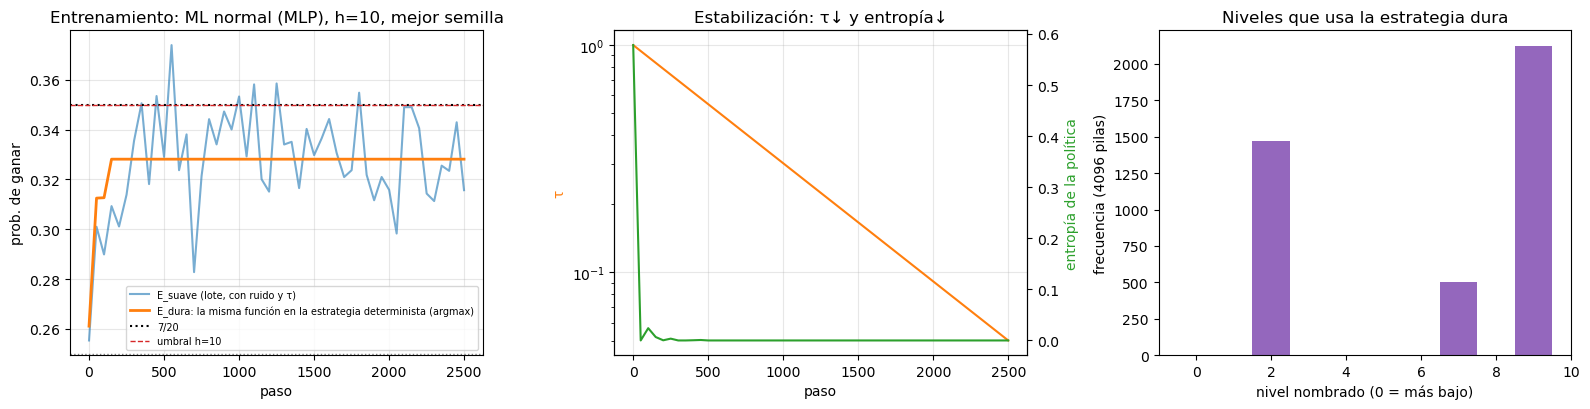

In [9]:
SEMILLAS = tuple(range(4))   # más semillas = más intentos (lo que importa es el MEJOR margen); cada una cuesta tiempo
LOTE, PASOS = 512, 2500      # iguales para todos los métodos (comparación justa de tiempo); súbelos para curvas más limpias
res = {}
experimento(res, "ML normal (MLP)", lambda h: PoliticaMLP(h, ancho=256, capas=3), hs=(8, 10, 12), semillas=SEMILLAS, lote=LOTE, steps=PASOS)
mejor10 = max(res[("ML normal (MLP)", 10)], key=lambda r: r["frac"]); graficar_entrenamiento(mejor10["hist"], mejor10["pol"], 10, "ML normal (MLP), h=10, mejor semilla")

  ML sobre bloques t=3 h=6    semilla 0:  95.185 % del umbral (déficit -69 victorias) | estabiliza en el paso    50 (  0.7 s de  51.3 s)   [51 s]
  ML sobre bloques t=3 h=6    semilla 1:  95.185 % del umbral (déficit -69 victorias) | estabiliza en el paso     0 (  0.0 s de  37.5 s)   [89 s]
  ML sobre bloques t=3 h=6    semilla 2:  99.930 % del umbral (déficit -1 victorias) | estabiliza en el paso    50 (  0.6 s de  42.1 s)   [131 s]
  ML sobre bloques t=3 h=6    semilla 3:  95.185 % del umbral (déficit -69 victorias) | estabiliza en el paso    50 (  0.5 s de  38.7 s)   [170 s]
  ML sobre bloques t=5 h=10   semilla 0:  93.837 % del umbral (déficit -2.26e+04 victorias) | estabiliza en el paso   150 (  2.9 s de  42.5 s)   [43 s]
  ML sobre bloques t=5 h=10   semilla 1:  93.837 % del umbral (déficit -2.26e+04 victorias) | estabiliza en el paso   100 (  1.0 s de  38.5 s)   [81 s]
  ML sobre bloques t=5 h=10   semilla 2:  93.837 % del umbral (déficit -2.26e+04 victorias) | estabiliza en el 

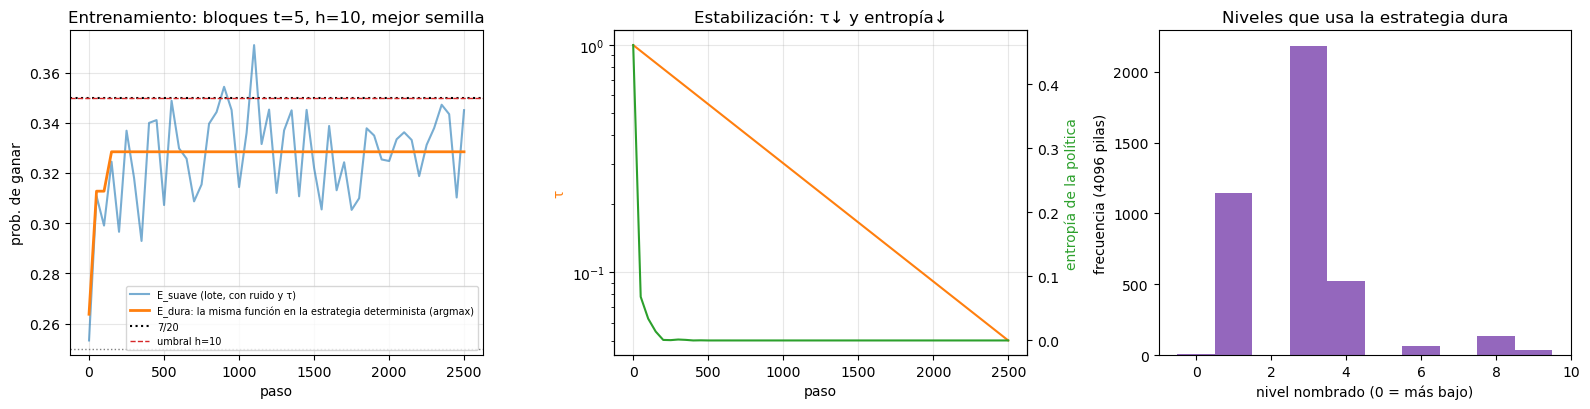

tabla del mejor t=5 (índices 1..5): [4, 2, 2, 4, 4, 2, 2, 4, 4, 5, 4, 4, 4, 5, 2, 4, 4, 2, 2, 4, 4, 2, 2, 4, 4, 5, 4, 4, 4, 5]   W' = 305 (W* = 327)


In [10]:
for t_ in (3, 5, 7):
    experimento(res, f"ML sobre bloques t={t_}", lambda h, t_=t_: PoliticaBloques(h, t_, param="mlp", ancho=128), hs=(2 * t_,), semillas=SEMILLAS, lote=LOTE, steps=PASOS)
mejor5 = max(res[("ML sobre bloques t=5", 10)], key=lambda r: r["frac"]); graficar_entrenamiento(mejor5["hist"], mejor5["pol"], 10, "bloques t=5, h=10, mejor semilla")
print("tabla del mejor t=5 (índices 1..5):", [int(v) + 1 for v in mejor5["k"]], "  W' =", mejor5["Wp"], "(W* = 327)")

método                 h corridas  mejor margen (victorias)  mejor % umbral  mejor W'-W*  segundos
ML normal (MLP)        8        4                     -1177         94.869%            -       246
ML normal (MLP)       10        4                -2.294e+04         93.750%            -       259
ML normal (MLP)       12        4                 -3.67e+05         93.750%            -       326
ML sobre bloques t=3   6        4                        -1         99.930%         +0.0       170
ML sobre bloques t=5  10        4                -2.262e+04         93.837%        -22.0       167
ML sobre bloques t=7  14        4                -4.818e+06         94.872%       -294.0       145

Corridas totales: 24   segundos de entrenamiento: 1313
Ninguna corrida supera el umbral (ni W - umbral > 0 ni W' - W* > 0): 7/20 no se mueve. (Un resultado negativo no prueba que no exista.)
Nota: con h finito, una tabla con W' = W* exacto da margen W - umbral < 0 (V_d < 7/20); el criterio de h infinito e

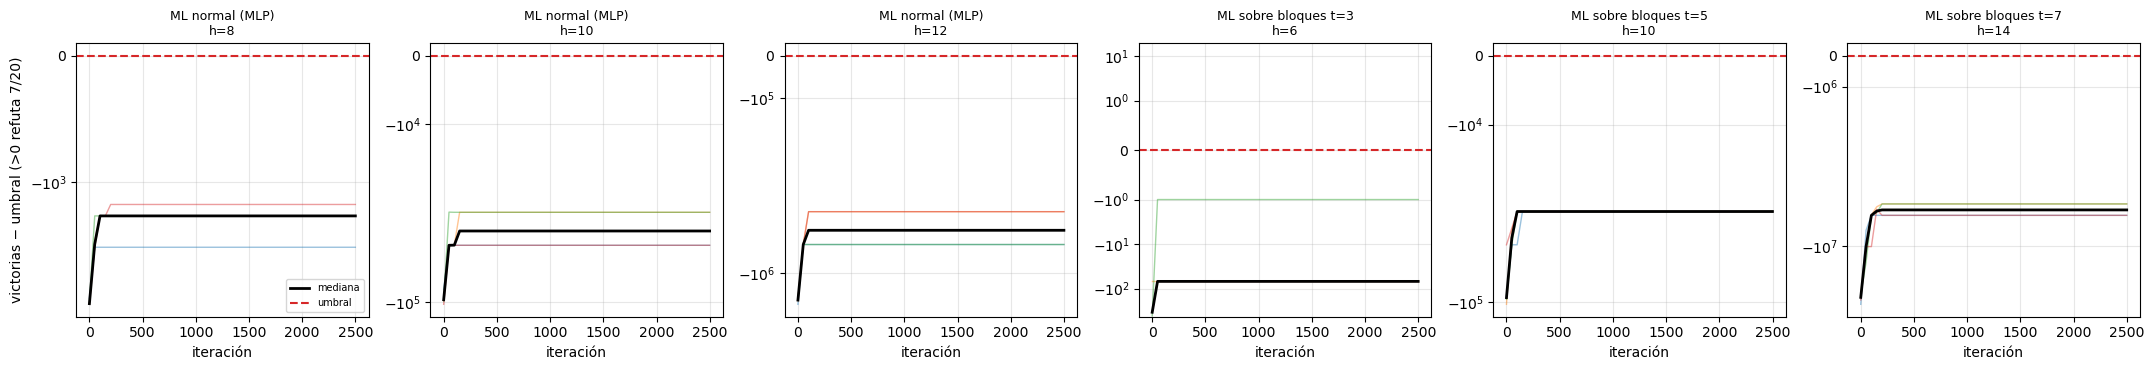

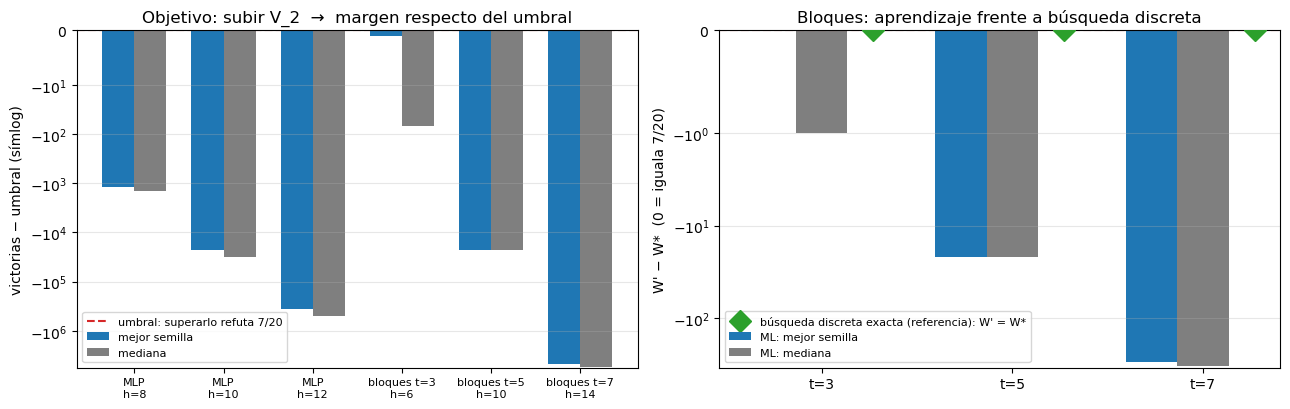

método                    h  n     % umbral (media±sd)  déficit medio  paso estab.  s estab.  s total
ML sobre bloques t=3      6  4          96.371 ± 2.055            -52           38       0.4     42.4
ML normal (MLP)           8  4          92.915 ± 2.143      -1.62e+03          100       2.3     61.4
ML normal (MLP)          10  4          91.518 ± 2.232      -3.11e+04           75       2.0     64.7
ML sobre bloques t=5     10  4          93.837 ± 0.000      -2.26e+04          112       1.5     41.8
ML normal (MLP)          12  4          91.518 ± 2.232      -4.98e+05           75       2.3     81.6
ML sobre bloques t=7     14  4          94.314 ± 0.558      -5.34e+06          162       1.7     36.3


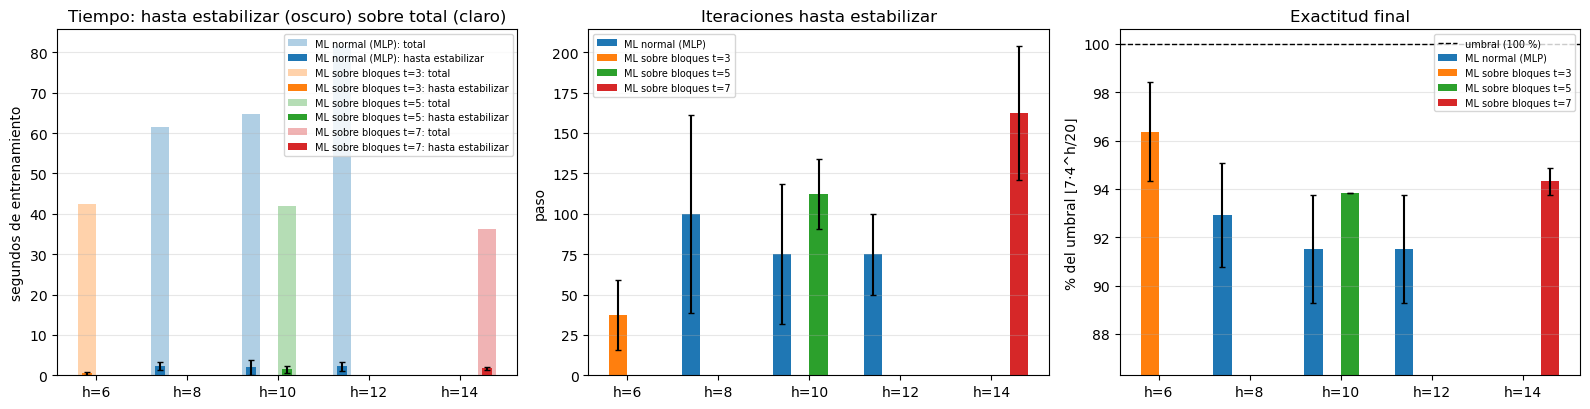

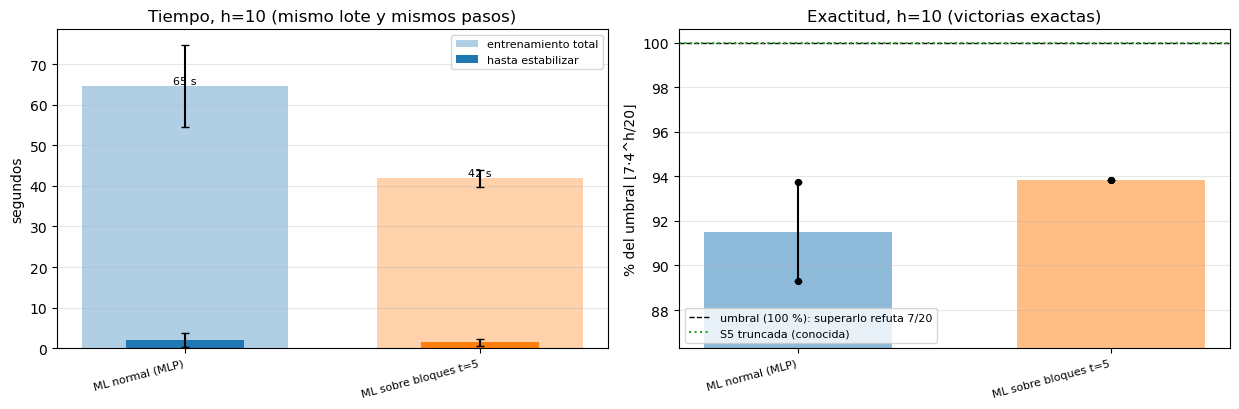

In [11]:
veredicto(res)
graficar_margen(res)                  # Fig. A: evolución del margen
graficar_balance(res)                 # Fig. B: mejor/mediana del margen, y aprendizaje vs búsqueda discreta
tabla_resumen(res)
graficar_tiempo_vs_h(res)             # Fig. C: tiempo hasta estabilizar (sobre el total), iteraciones y exactitud
graficar_metodos_mismo_h(res, 10)     # Fig. D: MLP vs bloques t=5 con el mismo h = 10